<a href="https://colab.research.google.com/github/olexvysotina-cell/ML/blob/main/%22%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9C%D0%9D_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2_%D0%92%D0%B8%D1%81%D0%BE%D1%82%D1%96%D0%BD%D0%B0_12_26_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [ ]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

# Додаємо кілька пропусків та аномалій для демонстрації підготовки даних
missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,112.980285
1,2022-01-02,118.725005
2,2022-01-03,115.930451
3,2022-01-04,114.862459
4,2022-01-05,94.078518


In [ ]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [ ]:
# Ваш код тут
df.tail(10)

,date,sales
1451,2025-12-22,171.328008
1452,2025-12-23,156.237492
1453,2025-12-24,160.161011
1454,2025-12-25,141.622914
1455,2025-12-26,130.154195
1456,2025-12-27,164.792801
1457,2025-12-28,172.113885
1458,2025-12-29,170.054977
1459,2025-12-30,160.035508
1460,2025-12-31,144.925047


In [ ]:
df["date"].min()

Timestamp('2022-01-01 00:00:00')

In [ ]:
df["date"].max()

Timestamp('2025-12-31 00:00:00')

In [ ]:
df['sales'].mean()

np.float64(128.86840539993554)

In [ ]:
df['sales'].median()

128.30740465635068

In [ ]:
df['sales'].std()

19.969577035218677

In [ ]:
df['sales'].min()

78.05403090053971

In [ ]:
df['sales'].max()

279.5724799225864

In [ ]:
df['date'].duplicated().sum()

np.int64(0)

## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [ ]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,112.980285
2022-01-02,118.725005
2022-01-03,115.930451
2022-01-04,114.862459
2022-01-05,94.078518


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [ ]:
# Ваш код тут
df_task = df.copy()

missing_indices = df_task.sample(n=5, random_state=42).index

df_task.loc[missing_indices, "sales"] = None

print(df_task[df_task["sales"].isna()])

            sales
date             
2023-02-18    NaN
2023-06-07    NaN
2024-06-11    NaN
2024-11-02    NaN
2025-01-10    NaN


In [ ]:
df_ffill = df_task.copy()
df_ffill["sales"] = df_ffill["sales"].ffill()

df_linear = df_task.copy()
df_linear["sales"] = df_linear["sales"].interpolate(method="linear")

df_time = df_task.copy()
df_time["sales"] = df_time["sales"].interpolate(method="time")

In [ ]:
comparison = pd.DataFrame({
    "date": missing_indices,
    "sales_before": df.loc[missing_indices, "sales"].values,
    "ffill": df_ffill.loc[missing_indices, "sales"].values,
    "linear": df_linear.loc[missing_indices, "sales"].values,
    "time": df_time.loc[missing_indices, "sales"].values
})

print(comparison.sort_values("date"))

        date  sales_before       ffill      linear        time
2 2023-02-18    137.977948  101.595618  121.705620  121.705620
3 2023-06-07    112.532130  130.269937  121.809579  121.809579
0 2024-06-11    145.670296  148.899627  142.339196  142.339196
4 2024-11-02    132.055906  129.367357  134.740349  134.740349
1 2025-01-10    124.321201  134.721514  144.255729  144.255729


Після порівняння трьох способів заповнення даних

## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

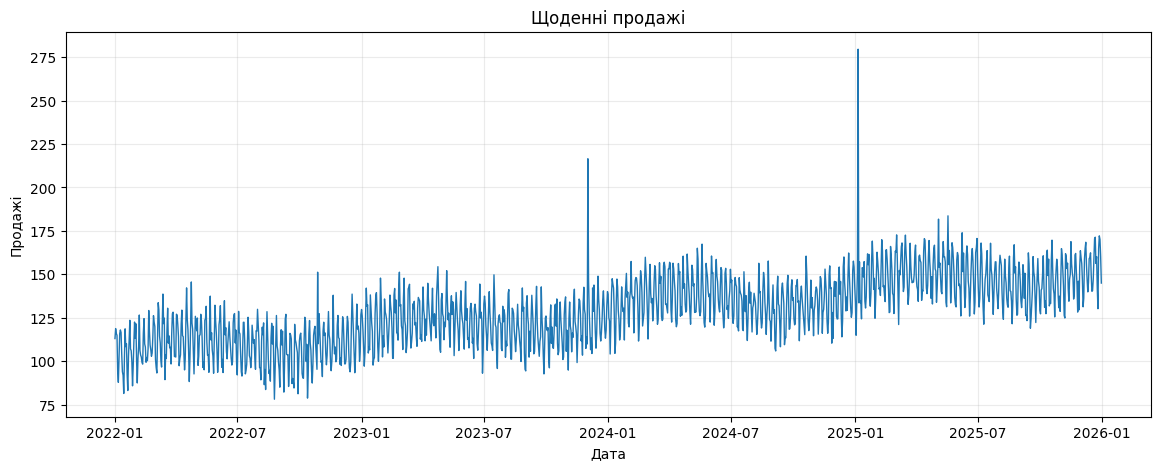

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

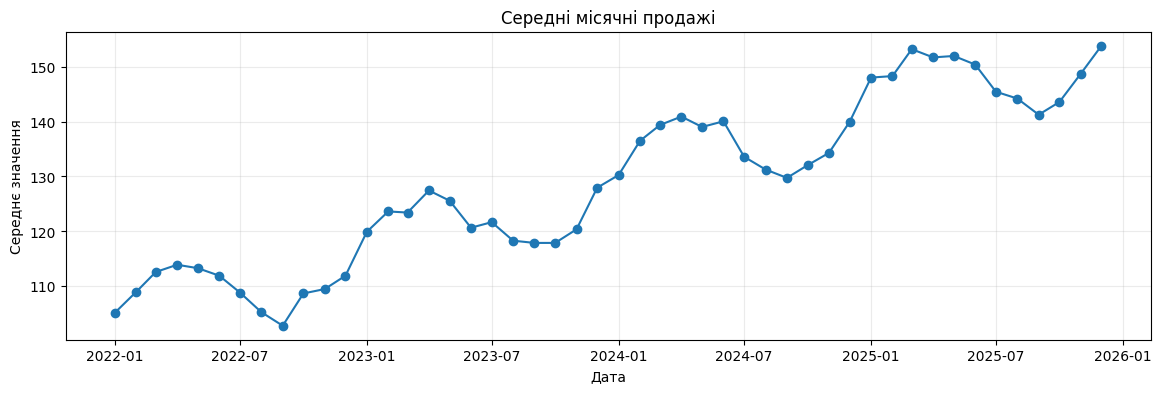

In [ ]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

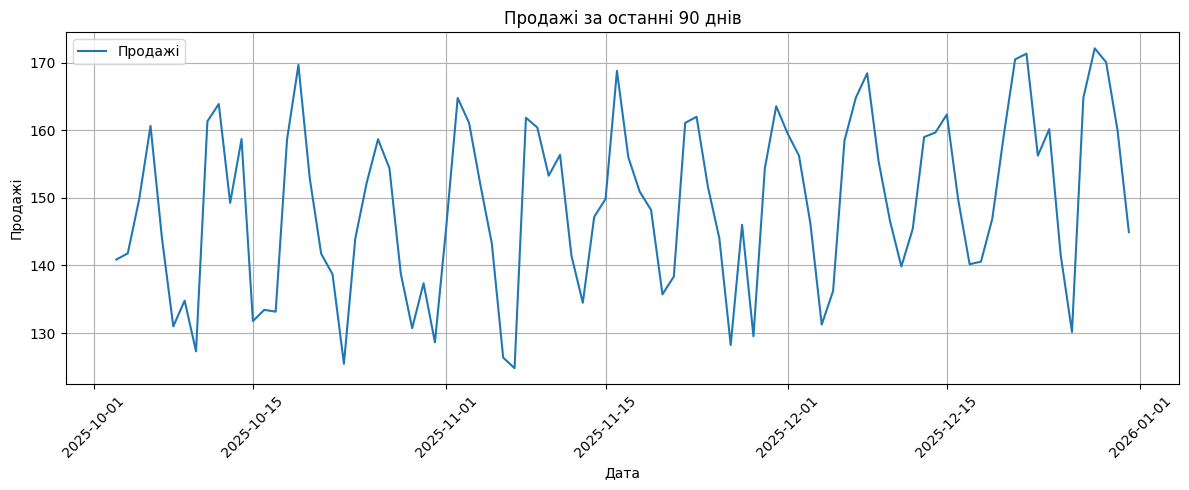

In [ ]:
#Ваш код тут
df2 = df.sort_index()

last_date = df2.index.max()

df_90 = df2[
    df2.index > last_date - pd.Timedelta(days=90)
].copy()

plt.figure(figsize=(12, 5))
plt.plot(df_90.index, df_90["sales"], label="Продажі")

plt.title("Продажі за останні 90 днів")
plt.xlabel("Дата")
plt.ylabel("Продажі")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

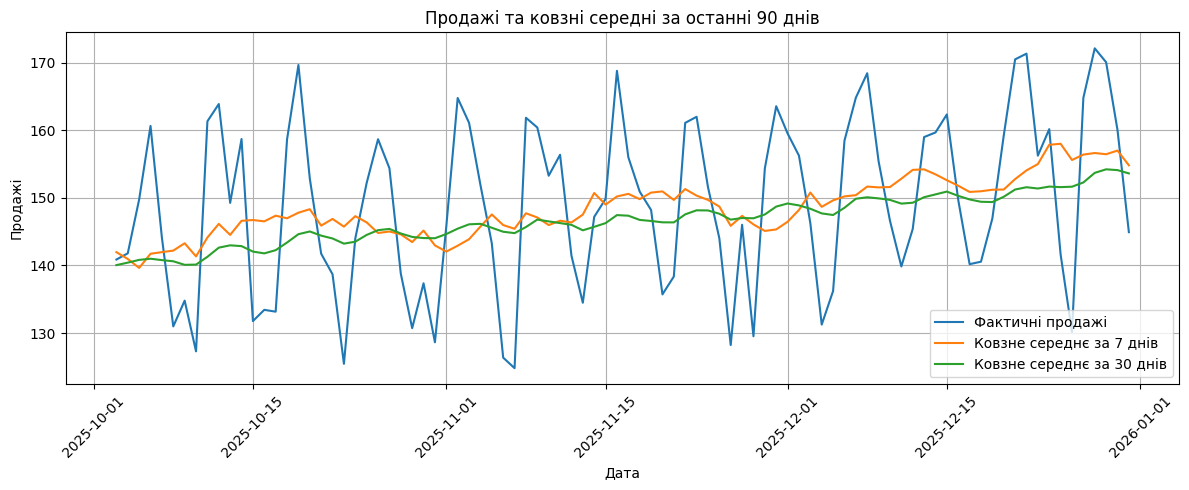

In [ ]:
df["MA_7"] = df["sales"].rolling(window=7).mean()
df["MA_30"] = df["sales"].rolling(window=30).mean()

df_90 = df[
    df.index > last_date - pd.Timedelta(days=90)
].copy()

plt.figure(figsize=(12, 5))

plt.plot(df_90.index, df_90["sales"], label="Фактичні продажі")
plt.plot(df_90.index, df_90["MA_7"], label="Ковзне середнє за 7 днів")
plt.plot(df_90.index, df_90["MA_30"], label="Ковзне середнє за 30 днів")

plt.title("Продажі та ковзні середні за останні 90 днів")
plt.xlabel("Дата")
plt.ylabel("Продажі")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

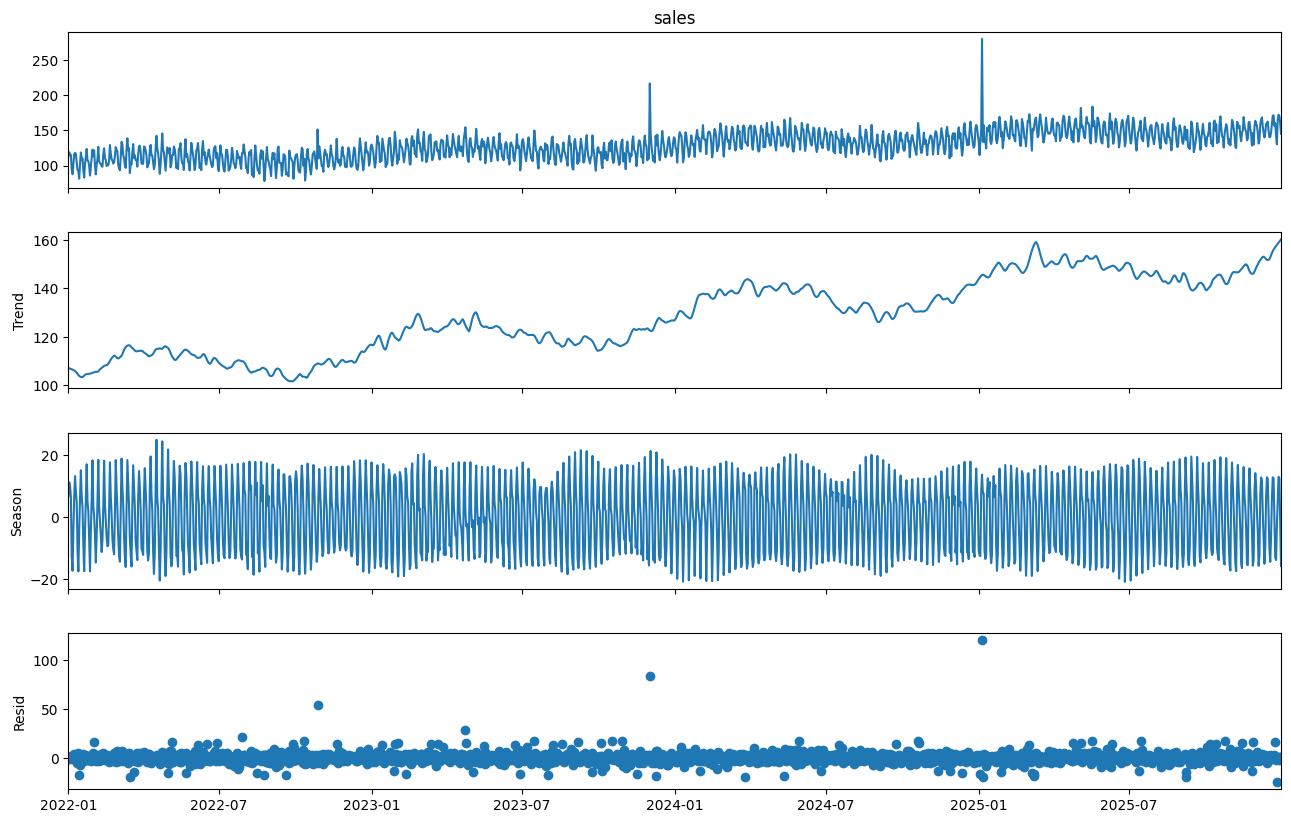

In [ ]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

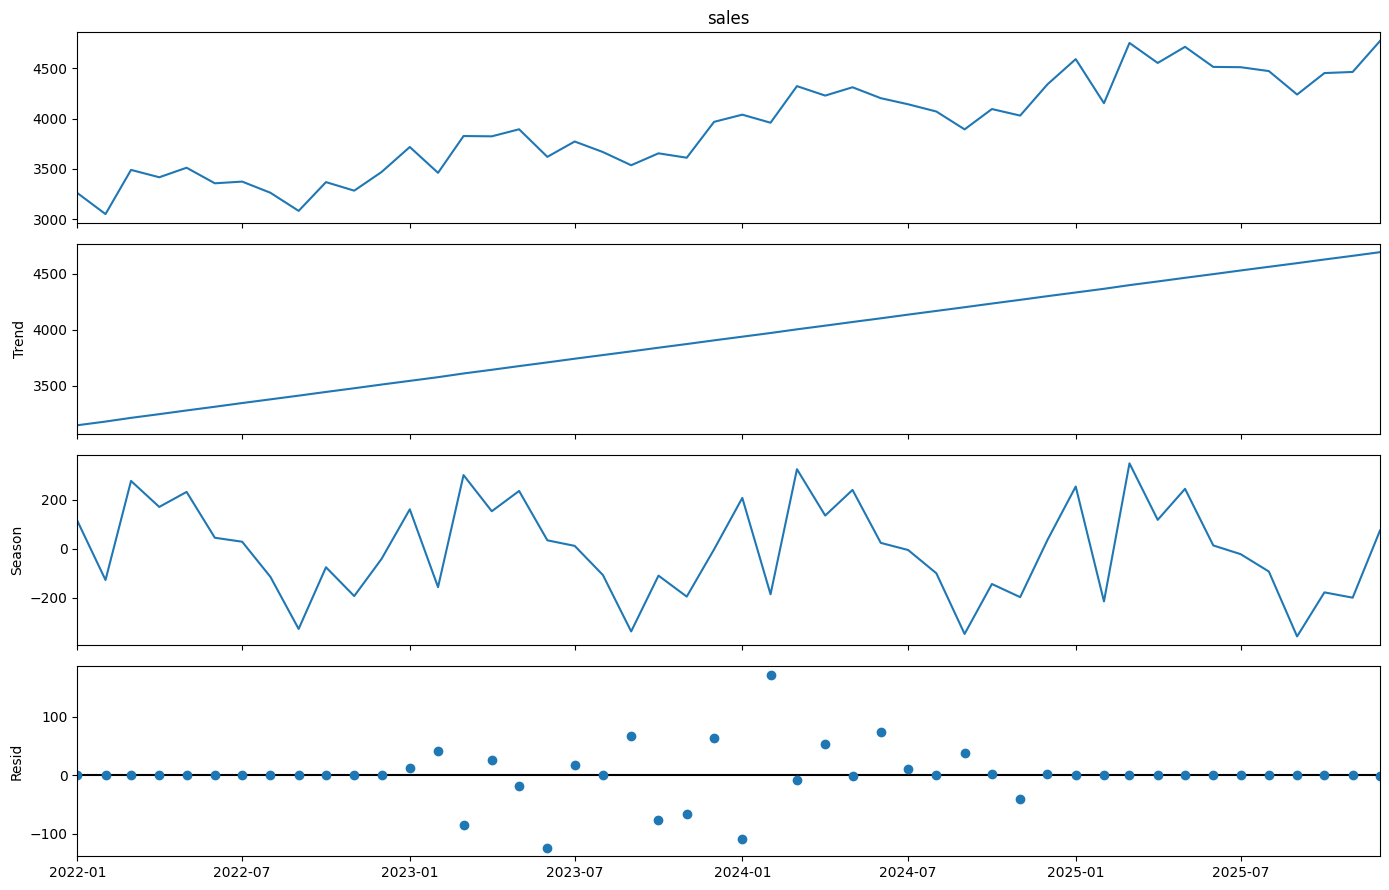

In [ ]:
# Ваш код тут

df3 = pd.to_datetime(df.index)

df = df.sort_index()

monthly_sales = df["sales"].resample("MS").sum(min_count=1)

# Заповнюємо пропущені значення, якщо вони є
monthly_sales = monthly_sales.interpolate(method="time")

# Виконуємо STL-декомпозицію
stl = STL(monthly_sales, period=12, robust=True)
stl_result = stl.fit()

# Будуємо графіки компонентів
fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
plt.show()

Для STL-декомпозиції щоденних даних про продажі обрано період сезонності 7, оскільки він відповідає одному тижню та дає змогу дослідити можливі повторювані коливання залежно від дня тижня. Сезонна складова демонструє чергування додатних і від’ємних значень. У залишках спостерігаються як невеликі відхилення, так і значні коливання, що можуть свідчити про нетипові зміни продажів, які не пояснюються трендом і сезонністю. Для остаточної оцінки загальної тенденції продажів необхідно проаналізувати повний графік тренду.

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [ ]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

Train: 2022-01-01 — 2025-10-02 1371
Test : 2025-10-03 — 2025-12-31 90


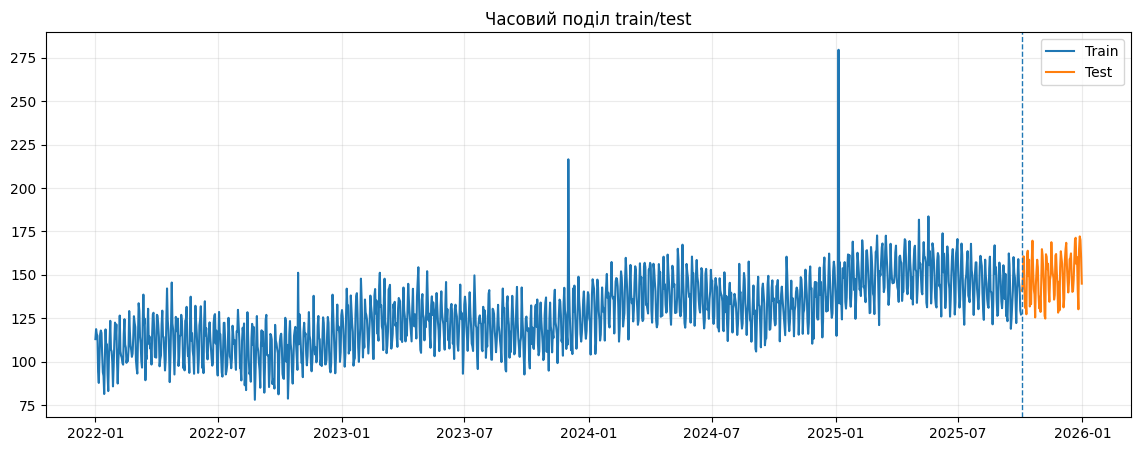

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [ ]:
# Ваш код тут
horizon = 60

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Кількість спостережень у train:", len(train))
print("Кількість спостережень у test:", len(test))
print("Остання дата train:", train.index.max().date())
print("Перша дата test:", test.index.min().date())

Кількість спостережень у train: 1401
Кількість спостережень у test: 60
Остання дата train: 2025-11-01
Перша дата test: 2025-11-02


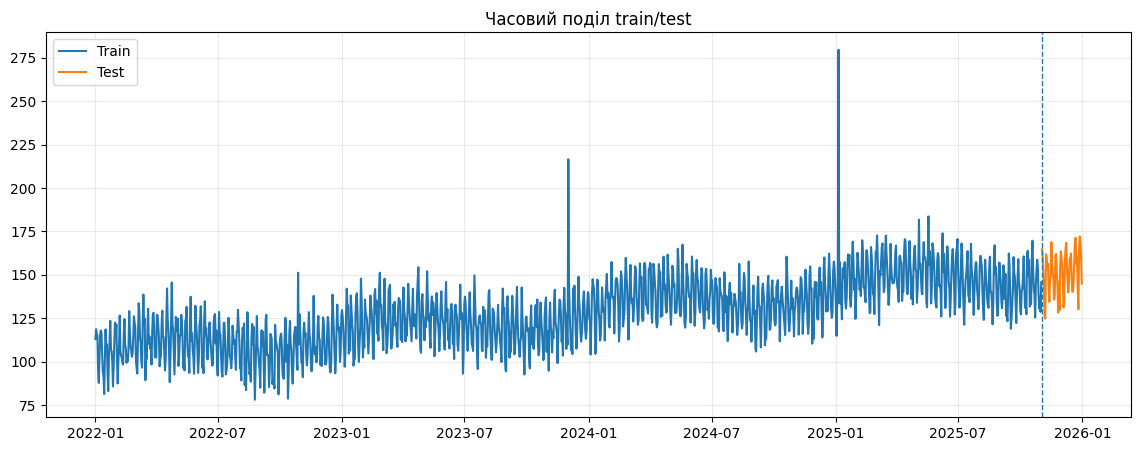

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [ ]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

,actual,naive,seasonal_naive
date,,,
2025-11-02,164.769682,145.781746,158.669587
2025-11-03,161.087756,145.781746,154.378728
2025-11-04,151.903340,145.781746,138.789478
2025-11-05,143.263305,145.781746,130.725589
2025-11-06,126.366294,145.781746,137.363586


## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

,MAE,RMSE,sMAPE_%,MASE
Naive,11.389437,13.495810,7.595040,1.601393
Seasonal naive,7.523370,9.241039,5.107073,1.057811


### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [ ]:
# Ваш код тут
print(results.idxmin())

MAE        Seasonal naive
RMSE       Seasonal naive
sMAPE_%    Seasonal naive
MASE       Seasonal naive
dtype: object


In [ ]:
# Фактичні значення за перші 30 днів
y_first_30 = test["sales"].iloc[:30]

# Фактичні значення за останні 30 днів
y_last_30 = test["sales"].iloc[30:]

# Прогноз Naive
naive_first_30 = naive_pred.iloc[:30] if isinstance(naive_pred, pd.Series) else naive_pred[:30]
naive_last_30 = naive_pred.iloc[30:] if isinstance(naive_pred, pd.Series) else naive_pred[30:]

# Прогноз Seasonal naive
seasonal_first_30 = seasonal_naive_pred.iloc[:30] if isinstance(seasonal_naive_pred, pd.Series) else seasonal_naive_pred[:30]
seasonal_last_30 = seasonal_naive_pred.iloc[30:] if isinstance(seasonal_naive_pred, pd.Series) else seasonal_naive_pred[30:]

# Таблиця MAE
mae_comparison = pd.DataFrame({
    "Перші 30 днів": [
        mean_absolute_error(y_first_30, naive_first_30),
        mean_absolute_error(y_first_30, seasonal_first_30)
    ],
    "Останні 30 днів": [
        mean_absolute_error(y_last_30, naive_last_30),
        mean_absolute_error(y_last_30, seasonal_last_30)
    ]
}, index=["Naive", "Seasonal naive"])

mae_comparison

,Перші 30 днів,Останні 30 днів
Naive,10.822231,11.956642
Seasonal naive,8.278954,6.767785


## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [ ]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

{'MAE': 6.417537801328749,
 'RMSE': np.float64(7.731200972731346),
 'sMAPE_%': np.float64(4.339169753097103),
 'MASE': np.float64(0.9023274292763365)}

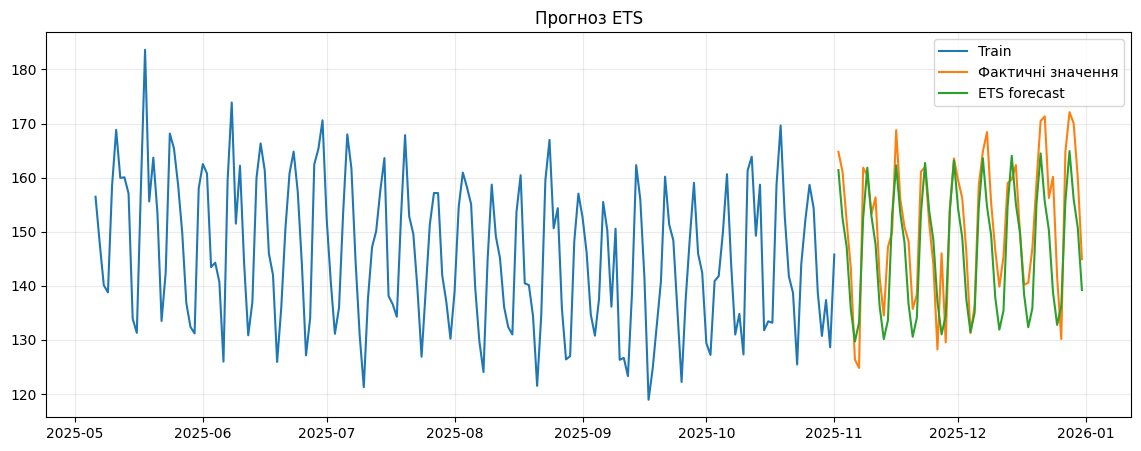

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

In [ ]:
# Ваш код тут

ets2 = ExponentialSmoothing(
    train["sales"],
    trend=None,
    seasonal="add",
    seasonal_periods=7
).fit()

ets2_pred = ets2.forecast(len(test))

In [ ]:
ets2_metrics = evaluate(
    test["sales"],
    ets2_pred,
    train["sales"],
    seasonality=7
)

print("ETS без тренду:")
print(ets2_metrics)

ETS без тренду:
{'MAE': 8.13710491347904, 'RMSE': np.float64(9.66218093404884), 'sMAPE_%': np.float64(5.524028706321665), 'MASE': np.float64(1.1441043567848033)}


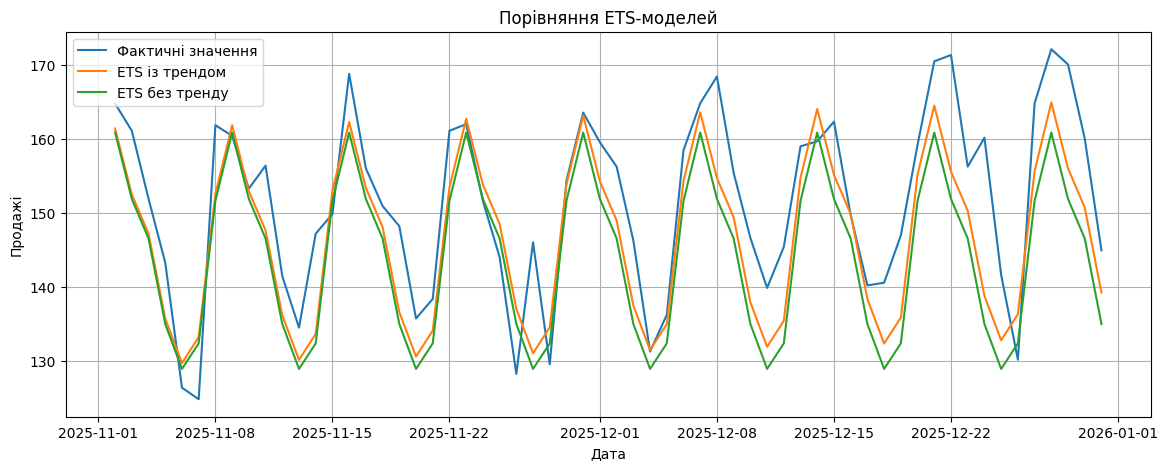

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(test.index, test["sales"], label="Фактичні значення")
plt.plot(test.index, ets_pred, label="ETS із трендом")
plt.plot(test.index, ets2_pred, label="ETS без тренду")

plt.title("Порівняння ETS-моделей")
plt.xlabel("Дата")
plt.ylabel("Продажі")
plt.legend()
plt.grid()
plt.show()

In [ ]:
results.loc["ETS із трендом"] = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

results.loc["ETS без тренду"] = evaluate(
    test["sales"],
    ets2_pred,
    train["sales"],
    seasonality=7
)

print(results)

                      MAE       RMSE   sMAPE_%      MASE
Naive           11.389437  13.495810  7.595040  1.601393
Seasonal naive   7.523370   9.241039  5.107073  1.057811
ETS із трендом   6.417538   7.731201  4.339170  0.902327
ETS без тренду   8.137105   9.662181  5.524029  1.144104


## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [ ]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

{'MAE': 8.254891279383138,
 'RMSE': np.float64(9.780364385952613),
 'sMAPE_%': np.float64(5.6020102934773455),
 'MASE': np.float64(1.1606655165380095)}

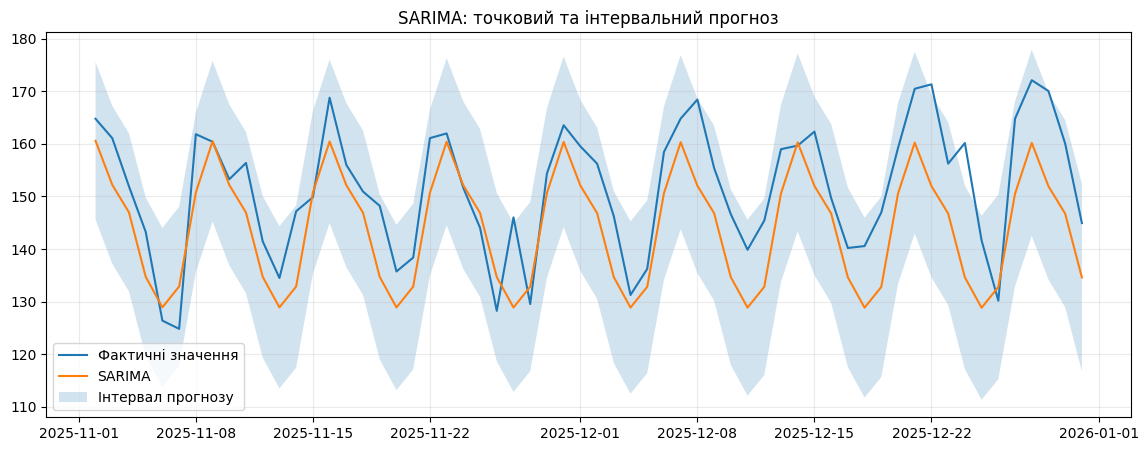

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [ ]:
# Ваш код тут
sarima_m2 = SARIMAX(
    train["sales"],
    order=(2, 1, 1),
    seasonal_order=(1, 1, 0, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_f2 = sarima_m2.get_forecast(steps=len(test))
sarima_p2 = sarima_f2.predicted_mean
sarima_ci2 = sarima_f2.conf_int()

sarima_metrics2 = evaluate(
    test["sales"],
    sarima_p2,
    train["sales"],
    seasonality=7
)

sarima_metrics2

{'MAE': 8.17824075041104,
 'RMSE': np.float64(9.776814748331757),
 'sMAPE_%': np.float64(5.543969314321419),
 'MASE': np.float64(1.1498881940038528)}

In [ ]:
comparison_sarima = pd.DataFrame({
    "SARIMA (1,1,1)(1,0,1,7)": sarima_metrics,
    "SARIMA (2,1,1)(1,1,0,7)": sarima_metrics2
})

print(comparison_sarima.loc[["MAE", "RMSE"]])

      SARIMA (1,1,1)(1,0,1,7)  SARIMA (2,1,1)(1,1,0,7)
MAE                  8.254891                 8.178241
RMSE                 9.780364                 9.776815


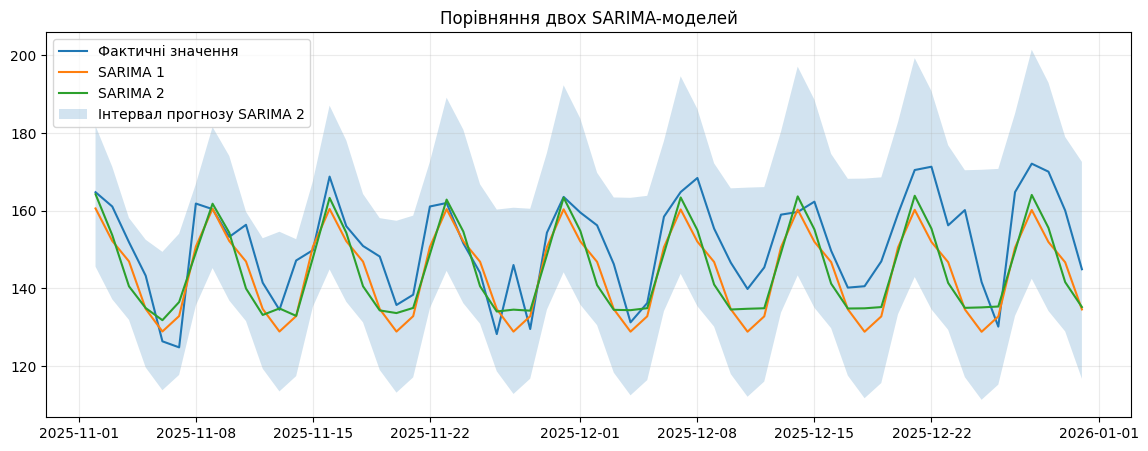

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA 1")
ax.plot(test.index, sarima_p2, label="SARIMA 2")

ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci2.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу SARIMA 2"
)

ax.legend()
ax.set_title("Порівняння двох SARIMA-моделей")
ax.grid(alpha=0.25)

plt.show()

## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [ ]:
!pip -q install prophet

In [ ]:
# Розкоментуйте, якщо Prophet встановлений.

from prophet import Prophet

prophet_train = (
     train.reset_index()
          .rename(columns={"date": "ds", "sales": "y"})
          )

model_prophet = Prophet(
     weekly_seasonality=True,
     yearly_seasonality=True,
     daily_seasonality=False,
     seasonality_mode="additive"
     )

model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(
     periods=len(test),
     freq="D"
     )

forecast = model_prophet.predict(future)

prophet_pred = (
     forecast.set_index("ds")
             .loc[test.index, "yhat"]
     )

evaluate(
     test["sales"],
     prophet_pred,
     train["sales"],
     seasonality=7
     )

{'MAE': 5.0353941326935745,
 'RMSE': np.float64(6.2284678940071485),
 'sMAPE_%': np.float64(3.4095662092313637),
 'MASE': np.float64(0.7079933743757295)}

### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

In [ ]:
# Ваш код тут

train_prophet = train.reset_index()
train_prophet = train_prophet.rename(
    columns={"date": "ds", "sales": "y"}
)

prophet_model = Prophet()
prophet_model.fit(train_prophet)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
future = test.reset_index()[["date"]].rename(
    columns={"date": "ds"}
)

prophet_forecast = prophet_model.predict(future)

prophet_pred = prophet_forecast["yhat"]

prophet_pred.head()

,yhat
0,161.850733
1,152.935288
2,147.660912
3,136.203091
4,130.250755


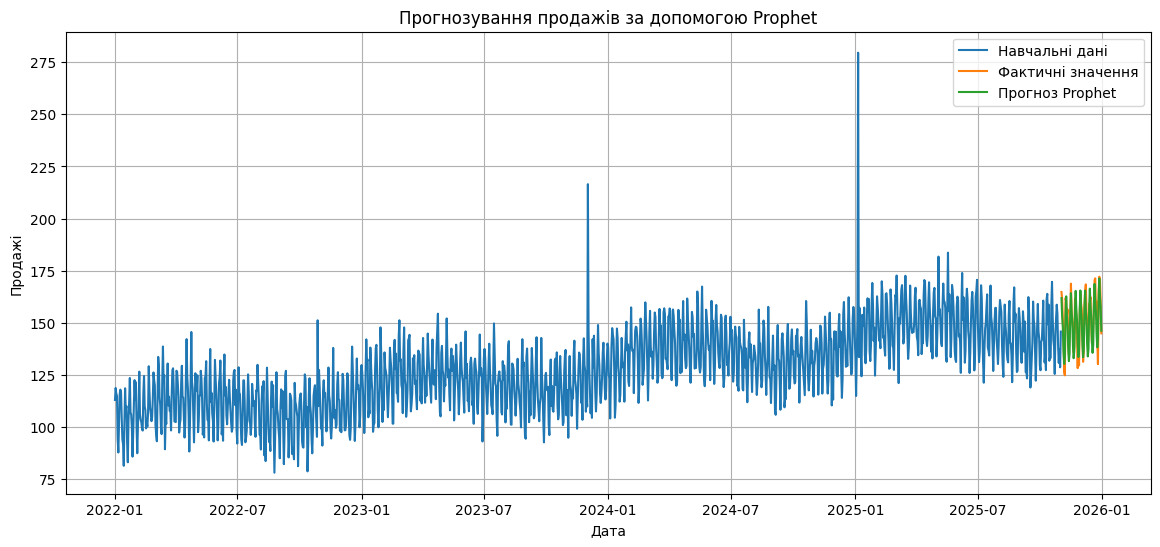

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(train.index, train["sales"], label="Навчальні дані")
plt.plot(test.index, test["sales"], label="Фактичні значення")
plt.plot(test.index, prophet_pred.values, label="Прогноз Prophet")

plt.title("Прогнозування продажів за допомогою Prophet")
plt.xlabel("Дата")
plt.ylabel("Продажі")
plt.legend()
plt.grid()
plt.show()

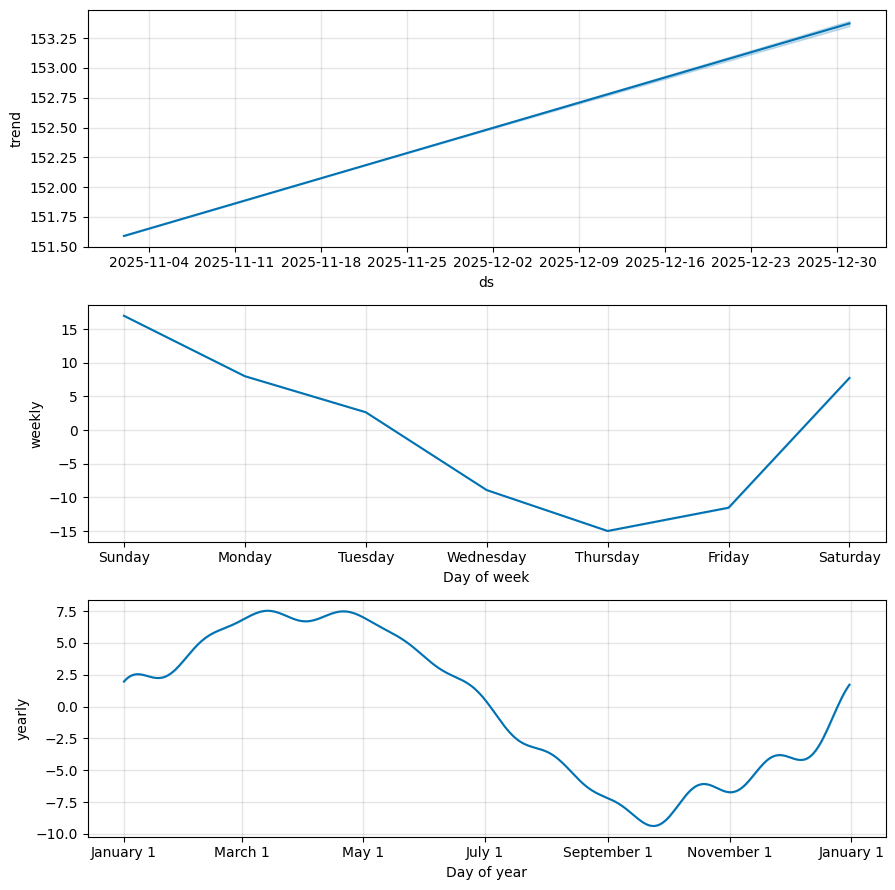

In [ ]:
prophet_model.plot_components(prophet_forecast)
plt.show()

In [ ]:
prophet_mae = mean_absolute_error(
    test["sales"],
    prophet_pred
)

print("MAE Prophet:", prophet_mae)

MAE Prophet: 5.0353941326935745


In [ ]:
mae_comparison = pd.DataFrame({
    "Модель": ["ETS", "SARIMA", "Prophet"],
    "MAE": [
        ets_metrics["MAE"],
        sarima_metrics["MAE"],
        prophet_mae
    ]
})

print(mae_comparison.sort_values("MAE"))

    Модель       MAE
2  Prophet  5.035394
0      ETS  6.417538
1   SARIMA  8.254891


За отриманими результатами найкращу точність прогнозування показала модель Prophet, оскільки вона має найменше значення MAE.



## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [ ]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend
date,,,,,,,,,,,,,,
2022-01-29,111.082231,97.400770,85.764899,99.669338,112.207900,102.048594,112.980285,104.512145,104.134824,11.932523,5,1,29,1
2022-01-30,122.474286,111.082231,97.400770,85.764899,123.513016,118.574712,118.725005,104.351335,104.067036,11.818566,6,1,30,1
2022-01-31,113.086640,122.474286,111.082231,97.400770,107.038953,108.356362,115.930451,104.202945,104.200939,11.541145,0,1,31,0
2022-02-01,121.472125,113.086640,122.474286,111.082231,105.990140,109.993414,114.862459,105.066901,104.099374,12.005835,1,2,32,0
2022-02-02,100.017166,121.472125,113.086640,122.474286,99.669338,92.413005,94.078518,107.278613,104.335434,13.533155,2,2,33,0


In [ ]:
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 5.85653967794482,
 'RMSE': np.float64(7.077433618357059),
 'sMAPE_%': np.float64(3.967126025599774),
 'MASE': np.float64(0.823449203674446)}

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [ ]:
# Ваш код тут
def make_features2(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 21, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)
    data["week_of_year"] = data.index.isocalendar().week.astype(int)


    return data

ml_df = make_features2(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_21,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend,week_of_year
date,,,,,,,,,,,,,,,,
2022-01-29,111.082231,97.400770,85.764899,99.669338,112.207900,102.048594,115.810618,112.980285,104.512145,104.134824,11.932523,5,1,29,1,4
2022-01-30,122.474286,111.082231,97.400770,85.764899,123.513016,118.574712,117.942615,118.725005,104.351335,104.067036,11.818566,6,1,30,1,4
2022-01-31,113.086640,122.474286,111.082231,97.400770,107.038953,108.356362,116.503128,115.930451,104.202945,104.200939,11.541145,0,1,31,0,5
2022-02-01,121.472125,113.086640,122.474286,111.082231,105.990140,109.993414,104.145515,114.862459,105.066901,104.099374,12.005835,1,2,32,0,5
2022-02-02,100.017166,121.472125,113.086640,122.474286,99.669338,92.413005,93.888812,94.078518,107.278613,104.335434,13.533155,2,2,33,0,5


In [ ]:
ml_df = make_features2(df["sales"]).dropna()

ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

from sklearn.ensemble import HistGradientBoostingRegressor

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)

ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 5.229454596565561,
 'RMSE': np.float64(6.844033520074309),
 'sMAPE_%': np.float64(3.540785002116309),
 'MASE': np.float64(0.7352789291960731)}

## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [ ]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

,MAE,RMSE,sMAPE_%,MASE
ML,5.229455,6.844034,3.540785,0.735279
ETS,6.417538,7.731201,4.339170,0.902327
Seasonal naive,7.523370,9.241039,5.107073,1.057811
SARIMA,8.254891,9.780364,5.602010,1.160666
Naive,11.389437,13.495810,7.595040,1.601393


### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Ваша відповідь:**

...

## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [ ]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-29,11.726037,22.703319
1,2023-12-29,2023-12-30,2024-01-26,6.347953,7.977381
2,2024-01-26,2024-01-27,2024-02-23,6.816896,7.867398
3,2024-02-23,2024-02-24,2024-03-22,5.245028,6.584598
4,2024-03-22,2024-03-23,2024-04-19,7.455005,9.252134
5,2024-04-19,2024-04-20,2024-05-17,6.096014,7.548739
6,2024-05-17,2024-05-18,2024-06-14,7.319789,9.073672
7,2024-06-14,2024-06-15,2024-07-12,6.137219,7.365825
8,2024-07-12,2024-07-13,2024-08-09,5.629306,6.705414
9,2024-08-09,2024-08-10,2024-09-06,6.042439,7.485644


In [ ]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

,MAE,RMSE
mean,7.299416,9.797419
std,1.943769,5.694299
min,5.245028,6.584598
max,14.629295,34.184076


### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

In [ ]:
# Ваш код тут
def rolling_seasonal_naive_cv2(series, initial=700, horizon=14, step=14, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results14 = rolling_seasonal_naive_cv2(
    df["sales"],
    initial=700,
    horizon=14,
    step=14,
    seasonality=7
)

cv_results14

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-15,17.867067,31.103862
1,2023-12-15,2023-12-16,2023-12-29,5.585008,7.964367
2,2023-12-29,2023-12-30,2024-01-12,6.810664,7.917761
3,2024-01-12,2024-01-13,2024-01-26,5.885242,8.036559
4,2024-01-26,2024-01-27,2024-02-09,6.367264,7.619978
5,2024-02-09,2024-02-10,2024-02-23,7.266528,8.107270
6,2024-02-23,2024-02-24,2024-03-08,6.017519,7.112335
7,2024-03-08,2024-03-09,2024-03-22,4.472537,6.010704
8,2024-03-22,2024-03-23,2024-04-05,7.551743,9.565627
9,2024-04-05,2024-04-06,2024-04-19,7.358267,8.927640


In [ ]:
print("Середня MAE для горизонту 28 днів:", cv_results["MAE"].mean())
print("Середня MAE для горизонту 14 днів:", cv_results14["MAE"].mean())

Середня MAE для горизонту 28 днів: 7.299416261220778
Середня MAE для горизонту 14 днів: 7.299416261220778


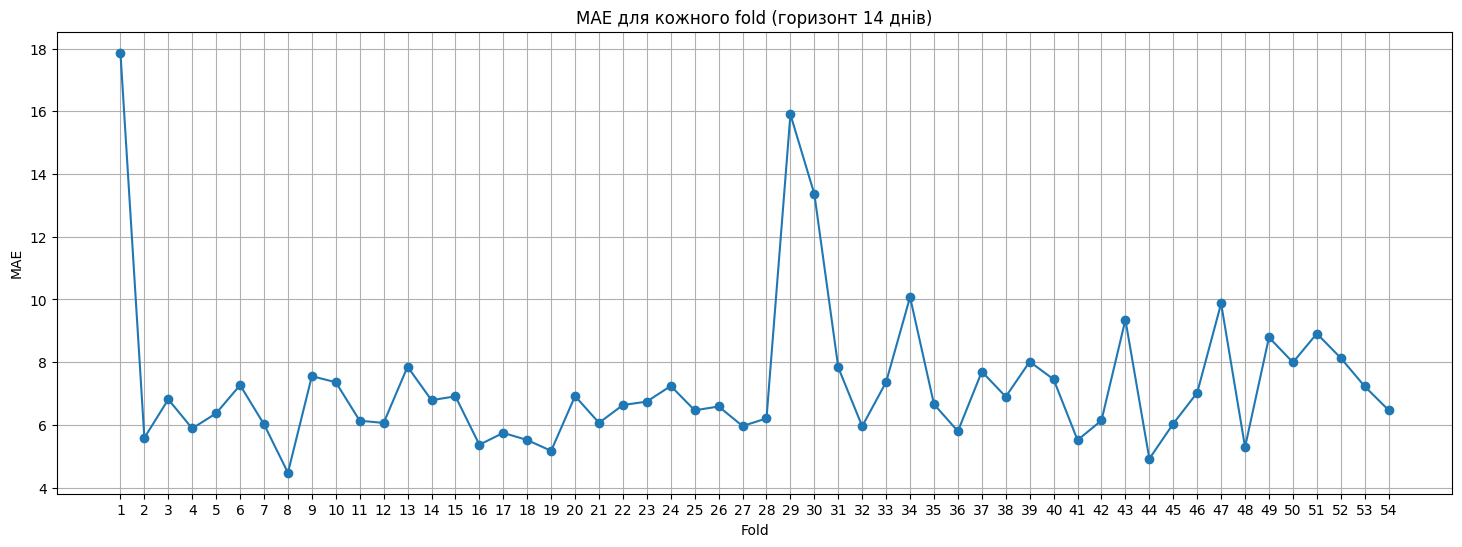

In [ ]:
plt.figure(figsize=(18, 6))

plt.plot(
    range(1, len(cv_results14) + 1),
    cv_results14["MAE"],
    marker="o"
)

plt.xlabel("Fold")
plt.ylabel("MAE")
plt.title("MAE для кожного fold (горизонт 14 днів)")
plt.xticks(range(1, len(cv_results14) + 1))
plt.grid(True)

plt.show()

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

In [ ]:
# Ваш код тут
forecast_result = sarima_model.get_forecast(steps=len(test))

forecast_ci = forecast_result.conf_int()

lower = forecast_ci.iloc[:, 0]
upper = forecast_ci.iloc[:, 1]

In [ ]:
y_test = test["sales"]

inside_interval = (y_test >= lower) & (y_test <= upper)

coverage = inside_interval.mean() * 100

print(f"Частка фактичних значень у межах інтервалу: {coverage:.2f}%")
print(f"У межах інтервалу: {inside_interval.sum()} із {len(y_test)} значень")

Частка фактичних значень у межах інтервалу: 93.33%
У межах інтервалу: 56 із 60 значень


## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [ ]:
# 1. Первинний аналіз
# Ваш код тут
print("Останні 10 рядків:", df['sales'].tail(10))
print("Мінімальне значення:", df['sales'].min())
print("Максимальне значення:", df['sales'].max())
print("Середнє значення:", df['sales'].mean())
print("Медіана:", df['sales'].median())
print("Квадратичне відхилення:", df['sales'].std())
print("Кількість дублікатів:", df['sales'].duplicated().sum())


Останні 10 рядків: date
2025-12-22    171.328008
2025-12-23    156.237492
2025-12-24    160.161011
2025-12-25    141.622914
2025-12-26    130.154195
2025-12-27    164.792801
2025-12-28    172.113885
2025-12-29    170.054977
2025-12-30    160.035508
2025-12-31    144.925047
Name: sales, dtype: float64
Мінімальне значення: 78.05403090053971
Максимальне значення: 279.5724799225864
Середнє значення: 128.86642728935436
Медіана: 128.2968988071915
Квадратичне відхилення: 19.95085111462701
Кількість дублікатів: 0


In [ ]:
# 2. Підготовка даних
# Ваш код тут

In [ ]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

# Перевіряємо кількість пропущених значень
print(df.isna().sum())

In [ ]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

In [ ]:
# 3. Візуалізація та STL
# Ваш код тут

In [ ]:
# 4. Train/test split
# Ваш код тут

In [ ]:
# 5. Seasonal naive baseline
# Ваш код тут

In [ ]:
# 6. Статистична модель
# Ваш код тут

In [ ]:
# 7. ML-модель
# Ваш код тут

In [ ]:
# 8. Порівняння метрик
# Ваш код тут

In [ ]:
# 9. Фінальний графік
# Ваш код тут

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

**Ваша відповідь:**

...

## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
2. Для чого потрібна базова модель?
3. Чим naive відрізняється від seasonal naive?
4. Що показує MAE?
5. Чому MAPE може бути проблемною за наявності нульових значень?
6. Що означає параметр сезонності `s` у SARIMA?
7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?
8. Що таке витік даних у часових рядах?
9. Навіщо потрібен rolling-origin backtesting?
10. Чому найскладніша модель не обов'язково дає найкращий прогноз?